# Image Branch — Phase 2: Model Construction

**Thesis:** Early detection of ASD in children aged 8 years or younger using multimodal machine learning

---

## Decisions taken from the audit

The audit (notebook 02) measured the contribution of each component of the signal:

| Variant | ROC-AUC | Interpretation |
|---|---|---|
| Full image | 0.8616 | Everything together |
| Face only | 0.8611 | Face with color and texture |
| Gray + normalized | 0.8374 | Texture without color |
| Landmark positions | 0.7116 | **Framing: strongest confounder** |
| No face | 0.6826 | Peripheral context |
| Flat mean color | 0.6762 | Global chromaticity |
| Geometric ratios | 0.5993 | Facial morphology |

Three independent confounders —framing, color and context— each reach between 0.68 and 0.71 on their own without processing any facial shape. Morphology, the only clinically interpretable component, stays at 0.5993 ± 0.0316.

**Consequently, this model is built as follows:**

1. **Input:** cropped face with per-image color normalization. This is the variant that minimizes the measured confounders.
2. **Parallel ablation model:** full image without normalization, to quantify how much performance came from the artifacts.
3. **Prior deduplication** and removal of the pairs that cross splits.
4. **Threshold calibrated on validation**, never on test.
5. **Likelihood ratio reported with a sensitivity range**, because capture artifacts do not reproduce outside this dataset.

## Warning that accompanies every result of this phase

The test set shares the same capture artifacts with the training set. Therefore **the metrics obtained here overestimate the performance to be expected on photographs taken by a caregiver with a phone**. This limitation cannot be corrected with these data: it requires validation on an independently collected cohort.

> **Repository `asd-screening-audit` · Notebook 3 of 5 — Image branch: frozen extractor (Phase 2)**
>
> Academic research on early ASD screening with public data. **This is not a diagnostic tool** and its results must not be used for clinical decisions.

| | |
|---|---|
| **Run order** | Notebooks 01 → 02 → 03 → 04 → 05. Notebook 05 requires the outputs of 01, 03 and 04 (optional); 01 and 02 are independent of each other. |
| **Inputs** | `data/imagenes/`. Conclusions of notebook 02. |
| **Outputs** | In `outputs/rama_imagenes_fase2/`: `rama_imagenes_salida_fusion.csv`, `rama_imagenes_parametros.json`, cross-validation and sensitivity tables. Model in `models/rama_imagenes/`. |
| **Hardware** | GPU recommended |
| **Data** | Source, license and folder layout: see `data/README.md` in the repository. |
| **Reproducibility** | Global seed `SEED = 42`. The first code cell defines `PROJECT_DIR`; there are no other hard-coded paths. |

> **Privacy.** Graphic outputs that show children's faces (example grids, crops, activation maps) were omitted from this repository. They are regenerated when the cells are run. All tables, metrics and aggregate plots are kept.

*File and folder names (`rama_imagenes_fase2`, ...) are kept in Spanish so that they match the original runs and the article.*

---
## 1. Environment and Configuration

In [1]:
# ==============================================================================
# CELL 1: Dependencies, paths and experiment configuration
# ==============================================================================
!pip install -q imagehash xgboost

import os, json, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import imagehash, cv2, joblib

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score,
                             f1_score, confusion_matrix, roc_curve,
                             classification_report, brier_score_loss)
import xgboost as xgb

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
SEED = 42
np.random.seed(SEED)

# Project paths. Only adjust PROJECT_DIR
# (outside Colab, set the environment variable ASD_PROJECT_DIR).
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = "/content/drive/MyDrive/asd-screening-audit"
except ImportError:
    PROJECT_DIR = os.environ.get("ASD_PROJECT_DIR", ".")

IMG_ROOT    = os.path.join(PROJECT_DIR, "data", "imagenes")
OUTPUTS_DIR = os.path.join(PROJECT_DIR, "outputs", "rama_imagenes_fase2")
MODELS_DIR  = os.path.join(PROJECT_DIR, "models", "rama_imagenes")
for d in (OUTPUTS_DIR, MODELS_DIR):
    os.makedirs(d, exist_ok=True)
assert os.path.isdir(IMG_ROOT), f"Does not exist: {IMG_ROOT}"

# ------------------------------ CONFIGURATION ---------------------------------
TAM          = 224
UMBRAL_HASH  = 5      # Hamming distance to consider near-duplicates (phash)
MARGEN_CARA  = 0.15   # relative margin around the face box
KAPPA        = 2.5    # clipping in standard deviations for the per-image normalization
# ------------------------------------------------------------------------------

ALIAS_CLASE = {'autism':'autism','autistic':'autism','asd':'autism',
               'typical':'typical','non_autistic':'typical','nonautistic':'typical',
               'normal':'typical','control':'typical'}
ALIAS_SPLIT = {'train':'train','test':'test','valid':'valid',
               'validation':'valid','val':'valid'}
EXT = {'.jpg','.jpeg','.png','.bmp','.webp'}
print("Entorno configurado.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 4.9 MB/s eta 0:00:00
Mounted at /content/drive
Entorno configurado.


### Environment versions

In [ ]:
# Environment versions (for the Methods section and requirements.txt)
import sys, platform, importlib.metadata as md
print("Python", sys.version.split()[0], "|", platform.platform())
for p in ["numpy", "pandas", "scipy", "scikit-learn", "xgboost", "tensorflow", "keras",
          "opencv-python", "imagehash", "shap", "statsmodels", "matplotlib", "seaborn",
          "joblib", "Pillow"]:
    try: print(f"{p:<16}{md.version(p)}")
    except Exception: print(f"{p:<16}(not installed)")
try:
    import tensorflow as tf; print("GPU:", [d.name for d in tf.config.list_physical_devices('GPU')])
except Exception: pass


---
## 2. Cohort: manifest, deduplication and splits

The manifest is rebuilt and the deduplication validated in notebook 02 is applied, using **phash** with threshold $\tau = 5$.

### 2.1 Handling of pairs that cross splits

The audit detected 3 pairs of the same image present in different splits. Keeping them would invalidate the evaluation: the model would see in training an image that later reappears in test.

The criterion applied is to **remove the copy on the training or validation side and keep the one in test**. This way the test set keeps its size and independence, which is what matters for estimating performance.

In [2]:
# ==============================================================================
# CELL 2: Manifest, deduplication and resolution of leaks between splits
# ==============================================================================
registros = []
for d_split in sorted(os.listdir(IMG_ROOT)):
    p_split = os.path.join(IMG_ROOT, d_split)
    if not os.path.isdir(p_split):
        continue
    split = ALIAS_SPLIT.get(d_split.strip().lower(), d_split.strip().lower())
    for d_clase in sorted(os.listdir(p_split)):
        p_clase = os.path.join(p_split, d_clase)
        if not os.path.isdir(p_clase):
            continue
        clase = ALIAS_CLASE.get(d_clase.strip().lower())
        if clase is None:
            continue
        for nombre in os.listdir(p_clase):
            if os.path.splitext(nombre)[1].lower() not in EXT:
                continue
            registros.append({'ruta': os.path.join(p_clase, nombre),
                              'archivo': nombre, 'split': split, 'clase': clase})

mf = pd.DataFrame(registros).reset_index(drop=True)
mf['target'] = (mf['clase'] == 'autism').astype(int)
print(f"Images indexed: {len(mf)}")
print(pd.crosstab(mf['split'], mf['clase'], margins=True))

# --- Perceptual hash ---
print("\nCalculando phash...")
H = []
for ruta in mf['ruta']:
    with Image.open(ruta) as im:
        H.append(np.asarray(imagehash.phash(im.convert('RGB'), hash_size=8).hash).flatten())
H = np.array(H, dtype=bool)

# --- Near-duplicate pairs ---
pares, BLOQUE = [], 400
for i0 in range(0, len(H), BLOQUE):
    blq = H[i0:i0+BLOQUE]
    d = (blq[:, None, :] != H[None, :, :]).sum(axis=2)
    for li, gi in zip(*np.where(d <= UMBRAL_HASH)):
        if i0 + li < gi:
            pares.append((i0 + li, int(gi), int(d[li, gi])))
print(f"Pairs with Hamming <= {UMBRAL_HASH}: {len(pares)}")

# --- Connected components (union-find) ---
padre = list(range(len(mf)))
def buscar(x):
    while padre[x] != x:
        padre[x] = padre[padre[x]]; x = padre[x]
    return x
for i, j, _ in pares:
    ri, rj = buscar(i), buscar(j)
    if ri != rj:
        padre[rj] = ri
mf['grupo'] = [buscar(k) for k in range(len(mf))]

# --- Contradictory labels ---
cpg = mf.groupby('grupo')['clase'].nunique()
contradictorios = set(cpg[cpg > 1].index)
print(f"Groups with contradictory labels: {len(contradictorios)}")

# --- One representative per group, prioritizing keeping the TEST copy ---
PRIORIDAD = {'test': 0, 'valid': 1, 'train': 2}
mf['_pri'] = mf['split'].map(PRIORIDAD)
cohorte = (mf[~mf.grupo.isin(contradictorios)]
           .sort_values('_pri')
           .drop_duplicates('grupo', keep='first')
           .drop(columns='_pri')
           .sort_index()
           .reset_index(drop=True))

print(f"\nDeduplicated cohort: {len(cohorte)} ({len(mf)-len(cohorte)} removed)")
print(pd.crosstab(cohorte['split'], cohorte['clase'], margins=True))

# --- Check: no group ends up split across partitions ---
cruces = cohorte.groupby('grupo')['split'].nunique()
assert (cruces == 1).all(), "Groups persist across more than one split"
print("\nVerified: no duplicate crosses splits.")
cohorte.to_csv(os.path.join(OUTPUTS_DIR, "cohorte_fase2.csv"), index=False)

Images indexed: 2801
clase  autism  typical   All
split                       
test      141      140   281
train    1210     1213  2423
valid      49       48    97
All      1400     1401  2801

Calculando phash...
Pairs with Hamming <= 5: 8
Groups with contradictory labels: 0

Deduplicated cohort: 2793 (8 removed)
clase  autism  typical   All
split                       
test      141      140   281
train    1205     1210  2415
valid      49       48    97
All      1395     1398  2793

Verified: no duplicate crosses splits.


---
## 3. Preprocessing: face crop and color normalization

### 3.1 Face crop

Detection with **YuNet** and a relative margin of 15 % to include the periocular region:

$$
\begin{aligned}
x_0 &= \max(0,\ x - 0.15\,w), & x_1 &= \min(W,\ x + w + 0.15\,w)\\
y_0 &= \max(0,\ y - 0.15\,h), & y_1 &= \min(H,\ y + h + 0.15\,h)
\end{aligned}
$$

### 3.2 Per-image color normalization

For each channel $c$, within each image:

$$\tilde{x}_{uvc} = \operatorname{clip}\!\left(\frac{x_{uvc} - \mu_c}{\sigma_c},\ -\kappa,\ \kappa\right), \qquad x^{\text{norm}}_{uvc} = \frac{\tilde{x}_{uvc} + \kappa}{2\kappa}\cdot 255$$

with $\kappa = 2.5$. This transformation removes global color and brightness shifts —the confounder that the audit quantified at AUC 0.6762— while preserving local contrast and structure.

Two **variants** are generated so they can be contrasted:

- `X_modelo`: cropped and normalized face → **input of the proposed model**
- `X_ablacion`: full image without normalization → **quantifies the contribution of the artifacts**

In [3]:
# ==============================================================================
# CELL 3: Face crop, normalization and variant generation
# ==============================================================================
MODELO_YUNET = '/content/face_detection_yunet_2023mar.onnx'
if not (os.path.exists(MODELO_YUNET) and os.path.getsize(MODELO_YUNET) > 100_000):
    for u in ['https://media.githubusercontent.com/media/opencv/opencv_zoo/main/'
              'models/face_detection_yunet/face_detection_yunet_2023mar.onnx',
              'https://github.com/opencv/opencv_zoo/raw/main/models/'
              'face_detection_yunet/face_detection_yunet_2023mar.onnx']:
        try:
            urllib.request.urlretrieve(u, MODELO_YUNET)
            if os.path.getsize(MODELO_YUNET) > 100_000:
                break
        except Exception:
            pass
yunet = cv2.FaceDetectorYN.create(MODELO_YUNET, "", (320, 320),
                                  score_threshold=0.5, nms_threshold=0.3)
print(f"YuNet loaded ({os.path.getsize(MODELO_YUNET):,} bytes)")

redim = lambda a: (np.zeros((TAM, TAM, 3), np.uint8) if a is None or a.size == 0
                   else np.asarray(Image.fromarray(a.astype(np.uint8))
                                   .resize((TAM, TAM), Image.BILINEAR)))

def normalizar(arr):
    """Per-channel z-score with clipping at KAPPA, rescaled to [0,255]."""
    a = arr.astype(np.float32)
    for c in range(3):
        m, s = a[..., c].mean(), a[..., c].std() + 1e-6
        a[..., c] = np.clip((a[..., c] - m) / s, -KAPPA, KAPPA)
    return (((a + KAPPA) / (2 * KAPPA)) * 255).astype(np.uint8)

print("\nProcessing images...")
X_modelo, X_ablacion, det = [], [], []
for k, r in cohorte.iterrows():
    if k % 400 == 0:
        print(f"   {k}/{len(cohorte)}")
    img = np.asarray(Image.open(r['ruta']).convert('RGB'))
    h, w = img.shape[:2]
    X_ablacion.append(redim(img))

    yunet.setInputSize((w, h))
    _, caras = yunet.detect(np.ascontiguousarray(img[:, :, ::-1]))
    if caras is not None and len(caras):
        x, y, bw, bh = [int(v) for v in max(caras, key=lambda c: c[2]*c[3])[:4]]
        mx, my = int(bw*MARGEN_CARA), int(bh*MARGEN_CARA)
        x0, y0 = max(0, x-mx), max(0, y-my)
        x1, y1 = min(w, x+bw+mx), min(h, y+bh+my)
        X_modelo.append(normalizar(redim(img[y0:y1, x0:x1])))
        det.append(True)
    else:
        X_modelo.append(normalizar(redim(img)))
        det.append(False)

X_modelo   = np.array(X_modelo, dtype=np.uint8)
X_ablacion = np.array(X_ablacion, dtype=np.uint8)
det        = np.array(det)
y_all      = cohorte['target'].to_numpy()
split_all  = cohorte['split'].to_numpy()

print(f"\nProcesadas: {len(X_modelo)} | face detected: {det.sum()} ({det.mean()*100:.1f}%)")

fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))
for c, i in enumerate(np.where(det)[0][:6]):
    axes[0, c].imshow(X_ablacion[i]); axes[0, c].axis('off')
    axes[1, c].imshow(X_modelo[i]);   axes[1, c].axis('off')
axes[0, 0].set_title("Ablation: full image", loc='left', fontweight='bold')
axes[1, 0].set_title("Model: normalized face", loc='left', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "fase2_entradas.png"), dpi=300)
plt.show()

YuNet loaded (232,589 bytes)

Processing images...
   0/2793
   400/2793
   800/2793
   1200/2793
   1600/2793
   2000/2793
   2400/2793

Procesadas: 2793 | face detected: 2793 (100.0%)


[Plot showing children's faces omitted from the repository for privacy. It is regenerated when the cell is run.]


---
## 4. Feature Extraction

**EfficientNetV2B0** pretrained on ImageNet is used, without classification layer and with global average pooling:

$$\mathbf{z}_i = f_\theta(x_i) \in \mathbb{R}^{1280}, \qquad \theta \text{ fixed}$$

### Why the extractor stays frozen

With 2,400 training images, fine-tuning a network of several million parameters overfits easily. And since the audit showed that the dataset contains strong capture confounders, **fine-tuning would learn those artifacts more effectively, not less**. Freezing $\theta$ and fitting only a classifier on the representations is the conservative decision and the one that best matches the available sample size.

The original split of the dataset is kept: `train` for fitting, `valid` for calibration and threshold, `test` for the single evaluation.

In [4]:
# ==============================================================================
# CELL 4: Embedding extraction with the frozen EfficientNetV2B0
# ==============================================================================
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetV2B0
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input

print("GPU disponible:", bool(tf.config.list_physical_devices('GPU')))
base = EfficientNetV2B0(include_top=False, weights='imagenet',
                        input_shape=(TAM, TAM, 3))
backbone = tf.keras.Model(base.input,
                          tf.keras.layers.GlobalAveragePooling2D()(base.output))
backbone.trainable = False

def extraer(arr, nombre, lote=64):
    print(f"   {nombre} ...")
    return np.vstack([backbone(preprocess_input(arr[i:i+lote].astype('float32')),
                               training=False).numpy()
                      for i in range(0, len(arr), lote)])

print("\nExtrayendo embeddings...")
Z_modelo   = extraer(X_modelo,   "normalized face")
Z_ablacion = extraer(X_ablacion, "full image")
print(f"Dimension: {Z_modelo.shape}")

i_tr = np.where(split_all == 'train')[0]
i_va = np.where(split_all == 'valid')[0]
i_te = np.where(split_all == 'test')[0]
print(f"\nTrain: {len(i_tr)} | Valid: {len(i_va)} | Test: {len(i_te)}")
print(f"Prevalence — train {y_all[i_tr].mean():.3f} | "
      f"valid {y_all[i_va].mean():.3f} | test {y_all[i_te].mean():.3f}")
np.savez_compressed(os.path.join(OUTPUTS_DIR, "embeddings_fase2.npz"),
                    Z_modelo=Z_modelo, Z_ablacion=Z_ablacion,
                    y=y_all, split=split_all, det=det)

GPU disponible: False
24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Extrayendo embeddings...
   normalized face ...
   full image ...
Dimension: (2793, 1280)

Train: 2415 | Valid: 97 | Test: 281
Prevalence — train 0.499 | valid 0.505 | test 0.502


---
## 5. Model and Ablation

A regularized **XGBoost** is fitted on the *embeddings*. The hyperparameters are conservative: with $d = 1280$ and $n \approx 2{,}400$, the risk of overfitting dominates that of underfitting.

Two models are fitted with an identical protocol:

- **Proposed model:** cropped and normalized face.
- **Ablation:** full image without normalization.

The difference between the two quantifies how much of the apparent performance came from the capture artifacts identified in the audit.

Stratified 10-fold cross-validation **on the training set only**.

In [5]:
# ==============================================================================
# CELL 5: Training and cross-validation (train only)
# ==============================================================================
def make_xgb():
    return xgb.XGBClassifier(
        n_estimators=300, max_depth=3, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.5, gamma=0.2,
        reg_alpha=0.5, reg_lambda=2.0, min_child_weight=5,
        random_state=SEED, eval_metric='logloss', tree_method='hist')

build = lambda: Pipeline([('scl', StandardScaler()), ('clf', make_xgb())])
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

resultados = {}
for nombre, Z in [('Model (normalized face)', Z_modelo),
                  ('Ablation (full image)',  Z_ablacion)]:
    print(f"\n{nombre} — 10-fold CV on train...")
    auc = cross_val_score(build(), Z[i_tr], y_all[i_tr], cv=cv, scoring='roc_auc')
    acc = cross_val_score(build(), Z[i_tr], y_all[i_tr], cv=cv, scoring='accuracy')
    resultados[nombre] = {'auc': auc, 'acc': acc}
    print(f"   ROC-AUC  : {auc.mean():.4f} ± {auc.std():.4f}")
    print(f"   Accuracy : {acc.mean()*100:.2f}% ± {acc.std()*100:.2f}%")

tabla_cv = pd.DataFrame([
    {'Model': k,
     'ROC-AUC': f"{v['auc'].mean():.4f} ± {v['auc'].std():.4f}",
     'Accuracy (%)': f"{v['acc'].mean()*100:.2f} ± {v['acc'].std()*100:.2f}"}
    for k, v in resultados.items()])
print("\n" + "=" * 84)
print(f" TABLE — 10-FOLD CROSS-VALIDATION ON TRAIN (n={len(i_tr)})")
print("=" * 84)
print(tabla_cv.to_string(index=False))
print("=" * 84)
d_auc = (resultados['Ablation (full image)']['auc'].mean()
         - resultados['Model (normalized face)']['auc'].mean())
print(f"\n Difference ablation - model: {d_auc:+.4f}")
print(" A positive difference measures the performance that the proposed model")
print(" deliberately GIVES UP by suppressing capture confounders.")
tabla_cv.to_csv(os.path.join(OUTPUTS_DIR, "tabla_cv_fase2.csv"), index=False)


Model (normalized face) — 10-fold CV on train...
   ROC-AUC  : 0.8695 ± 0.0322
   Accuracy : 78.92% ± 3.93%

Ablation (full image) — 10-fold CV on train...
   ROC-AUC  : 0.8786 ± 0.0320
   Accuracy : 79.46% ± 4.01%

 TABLE — 10-FOLD CROSS-VALIDATION ON TRAIN (n=2415)
                     Model         ROC-AUC Accuracy (%)
Model (normalized face) 0.8695 ± 0.0322 78.92 ± 3.93
 Ablation (full image) 0.8786 ± 0.0320 79.46 ± 4.01

 Difference ablation - model: +0.0091
 A positive difference measures the performance that the proposed model
 deliberately GIVES UP by suppressing capture confounders.


---
## 6. Calibration and Threshold Selection

### 6.1 Calibration

XGBoost produces poorly calibrated scores: its output ranks well but cannot be interpreted as a probability. Late fusion needs reliable probabilities, so **Platt scaling** is applied through internal cross-validation on the training set:

$$p_{\text{cal}} = \sigma\!\left(a \cdot s + b\right)$$

where $s$ is the raw score and $(a, b)$ are fitted by maximum likelihood.

Quality is evaluated with the **Brier score**, the mean squared error between predicted probability and observed outcome:

$$\text{BS} = \frac{1}{n}\sum_{i=1}^{n}\left(p_i - y_i\right)^2$$

### 6.2 Operating threshold

It is chosen by the **Youden J index** on the **validation** set:

$$J = \text{Se} + \text{Sp} - 1, \qquad \tau^\star = \arg\max_\tau J(\tau)$$

The test set plays no part in this choice and is evaluated only once.

In [6]:
# ==============================================================================
# CELL 6: Calibration on train and threshold on valid
# ==============================================================================
modelo = Pipeline([('scl', StandardScaler()), ('clf', make_xgb())])
calibrado = CalibratedClassifierCV(modelo, method='sigmoid', cv=5)
calibrado.fit(Z_modelo[i_tr], y_all[i_tr])
print("Model calibrated on train (Platt, 5 inner folds).")

p_va = calibrado.predict_proba(Z_modelo[i_va])[:, 1]
fpr_v, tpr_v, thr_v = roc_curve(y_all[i_va], p_va)
UMBRAL = float(thr_v[np.argmax(tpr_v - fpr_v)])

print("\n" + "=" * 72)
print(" THRESHOLD SELECTION — VALIDATION SET")
print("=" * 72)
print(f"  validation n   : {len(i_va)}")
print(f"  ROC-AUC valid  : {roc_auc_score(y_all[i_va], p_va):.4f}")
print(f"  Max. J index   : {(tpr_v - fpr_v).max():.4f}")
print(f"  Threshold      : {UMBRAL:.4f}   <-- frozen before touching test")
print(f"  Brier (valid)  : {brier_score_loss(y_all[i_va], p_va):.4f}")
print("=" * 72)
print("\n [!] The validation set is small, so the threshold")
print("     has appreciable variance. It must be declared as a limitation.")

Model calibrated on train (Platt, 5 inner folds).

 THRESHOLD SELECTION — VALIDATION SET
  validation n   : 97
  ROC-AUC valid  : 0.8682
  Max. J index   : 0.6297
  Threshold      : 0.3676   <-- frozen before touching test
  Brier (valid)  : 0.1653

 [!] The validation set is small, so the threshold
     has appreciable variance. It must be declared as a limitation.


---
## 7. Single Evaluation on the Test Set

The test set is evaluated **only once**, with the threshold already frozen. The likelihood ratios that feed late fusion come from here:

$$LR^+ = \frac{\text{Se}}{1 - \text{Sp}}, \qquad LR^- = \frac{1 - \text{Se}}{\text{Sp}}$$

 TEST EVALUATION (n=281) — THRESHOLD 0.3676 FIXED ON VALID
  Accuracy      : 80.43%
  Sensitivity   : 88.65%  (125/141)
  Specificity   : 72.14%  (101/140)
  F1-Score      : 81.97%
  ROC-AUC       : 0.9091
  Brier Score   : 0.1276

  LR+ : 3.182     LR- : 0.157

              precision    recall  f1-score   support

     typical       0.86      0.72      0.79       140
      autism       0.76      0.89      0.82       141

    accuracy                           0.80       281
   macro avg       0.81      0.80      0.80       281
weighted avg       0.81      0.80      0.80       281



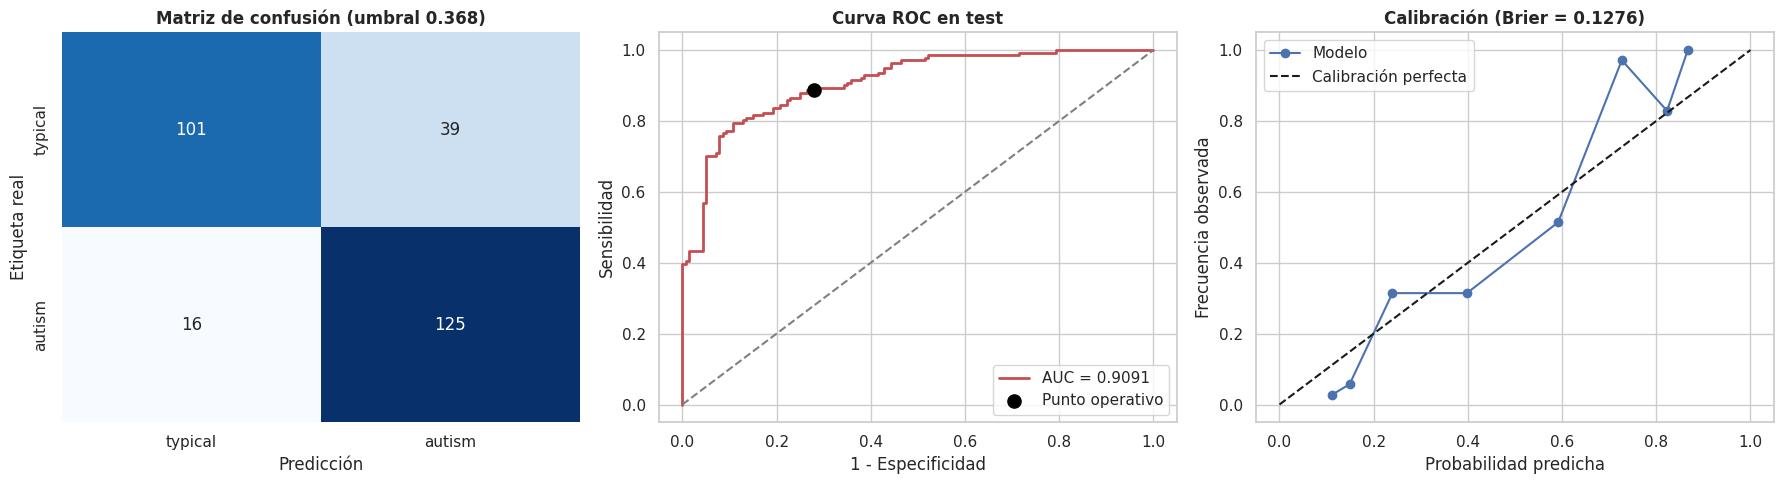

In [7]:
# ==============================================================================
# CELL 7: Test evaluation and likelihood ratio computation
# ==============================================================================
p_te = calibrado.predict_proba(Z_modelo[i_te])[:, 1]
y_te = y_all[i_te]
pred = (p_te >= UMBRAL).astype(int)

cm = confusion_matrix(y_te, pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
SENS  = tp / (tp + fn)
ESPEC = tn / (tn + fp)
AUC   = roc_auc_score(y_te, p_te)
BRIER = brier_score_loss(y_te, p_te)
LR_POS = SENS / (1 - ESPEC) if ESPEC < 1 else np.inf
LR_NEG = (1 - SENS) / ESPEC if ESPEC > 0 else np.inf

print("=" * 72)
print(f" TEST EVALUATION (n={len(i_te)}) — THRESHOLD {UMBRAL:.4f} FIXED ON VALID")
print("=" * 72)
print(f"  Accuracy      : {accuracy_score(y_te, pred)*100:.2f}%")
print(f"  Sensitivity   : {SENS*100:.2f}%  ({tp}/{tp+fn})")
print(f"  Specificity   : {ESPEC*100:.2f}%  ({tn}/{tn+fp})")
print(f"  F1-Score      : {f1_score(y_te, pred)*100:.2f}%")
print(f"  ROC-AUC       : {AUC:.4f}")
print(f"  Brier Score   : {BRIER:.4f}")
print(f"\n  LR+ : {LR_POS:.3f}     LR- : {LR_NEG:.3f}")
print("=" * 72)
print("\n" + classification_report(y_te, pred,
                                   target_names=['typical', 'autism']))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['typical', 'autism'], yticklabels=['typical', 'autism'])
axes[0].set_title(f"Confusion matrix (threshold {UMBRAL:.3f})", fontweight='bold')
axes[0].set_xlabel("Prediction"); axes[0].set_ylabel("True label")

f_, t_, _ = roc_curve(y_te, p_te)
axes[1].plot(f_, t_, color='#C44E52', lw=2, label=f'AUC = {AUC:.4f}')
axes[1].plot([0, 1], [0, 1], '--', c='gray')
axes[1].scatter([1-ESPEC], [SENS], s=90, c='black', zorder=5, label='Operating point')
axes[1].set_title("ROC curve on test", fontweight='bold')
axes[1].set_xlabel("1 - Specificity"); axes[1].set_ylabel("Sensitivity")
axes[1].legend(loc='lower right')

pt, pp = calibration_curve(y_te, p_te, n_bins=8, strategy='quantile')
axes[2].plot(pp, pt, 'o-', color='#4C72B0', label='Model')
axes[2].plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
axes[2].set_title(f"Calibration (Brier = {BRIER:.4f})", fontweight='bold')
axes[2].set_xlabel("Predicted probability"); axes[2].set_ylabel("Observed frequency")
axes[2].legend(loc='upper left')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "fase2_evaluacion_test.png"), dpi=300)
plt.show()

In [8]:
# ==============================================================================
# CELL 7b: Split audit, calibration and confidence intervals
# Runs AFTER CELL 7 (uses Z_modelo, y_all, i_tr, i_va, i_te, p_va, p_te,
# y_te, UMBRAL, cohorte and OUTPUTS_DIR, defined in the previous cells).
# Does not require face detection: it uses the embeddings already extracted.
# ==============================================================================
from sklearn.linear_model import LogisticRegression
rng = np.random.default_rng(SEED)

def l2(Z): return Z / (np.linalg.norm(Z, axis=1, keepdims=True) + 1e-12)
Zn = l2(Z_modelo)

# ------------------------------------------------------------------------------
# PART A — Are there test images nearly identical to train images?
# ------------------------------------------------------------------------------
print("=" * 88)
print(" PART A — COSINE SIMILARITY TO THE NEAREST NEIGHBOR ACROSS SPLITS")
print("=" * 88)
S_te_tr = Zn[i_te] @ Zn[i_tr].T
nn_sim  = S_te_tr.max(axis=1)                       # test -> train
nn_idx  = i_tr[S_te_tr.argmax(axis=1)]
S_tr_tr = Zn[i_tr] @ Zn[i_tr].T
np.fill_diagonal(S_tr_tr, -1)
ref_sim = S_tr_tr.max(axis=1)                       # train -> rest of train (reference)
S_va_tr = Zn[i_va] @ Zn[i_tr].T
va_sim  = S_va_tr.max(axis=1)

def q(v): return {f"p{p}": round(float(np.percentile(v, p)), 4) for p in (50, 90, 99, 100)}
print(f" test  -> train : {q(nn_sim)}")
print(f" valid -> train : {q(va_sim)}")
print(f" train -> train : {q(ref_sim)}   (reference: duplicates WITHIN train)")
agree = (y_all[nn_idx] == y_all[i_te]).mean()
print(f"\n Label agreement with the nearest neighbor in train: {agree*100:.1f}%")

TAUS = (0.90, 0.95, 0.98)
for t in TAUS:
    print(f" Test images with similarity >= {t:.2f} to some train image: "
          f"{int((nn_sim >= t).sum())} de {len(i_te)}")

pares = pd.DataFrame({'ruta_test': cohorte.loc[i_te, 'ruta'].values,
                      'ruta_vecino_train': cohorte.loc[nn_idx, 'ruta'].values,
                      'similitud': nn_sim,
                      'misma_clase': (y_all[nn_idx] == y_all[i_te])}
                     ).sort_values('similitud', ascending=False)
pares.to_csv(os.path.join(OUTPUTS_DIR, "auditoria_vecinos_test_train.csv"), index=False)
print(" Most similar pairs saved in auditoria_vecinos_test_train.csv"
      " (review the first ones visually).")

# Re-evaluation of the test set without the images nearly identical to train
def met(y, p, thr):
    pr = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pr, labels=[0, 1]).ravel()
    return dict(n=len(y), AUROC=roc_auc_score(y, p), Accuracy=(tp + tn) / len(y),
                Sensibilidad=tp / (tp + fn), Especificidad=tn / (tn + fp),
                Precision=tp / (tp + fp) if tp + fp else np.nan)
filas = [{'Test': 'Completo', **met(y_te, p_te, UMBRAL)}]
for t in TAUS:
    k = nn_sim < t
    if k.sum() > 30 and len(np.unique(y_te[k])) == 2:
        filas.append({'Test': f'No images with similarity >= {t:.2f}', **met(y_te[k], p_te[k], UMBRAL)})
RE = pd.DataFrame(filas)
print("\n TEST RE-EVALUATED EXCLUDING IMAGES NEARLY IDENTICAL TO TRAIN (same threshold)")
print(RE.round(4).to_string(index=False))
RE.to_csv(os.path.join(OUTPUTS_DIR, "test_sin_vecinos_cercanos.csv"), index=False)

# ------------------------------------------------------------------------------
# PART B — Calibration and confidence intervals (stratified bootstrap)
# ------------------------------------------------------------------------------
print("\n" + "=" * 88)
print(" PART B — CALIBRATION AND INTERVALS (test, B = 2000, stratified bootstrap)")
print("=" * 88)
def logit(p): p = np.clip(p, 1e-4, 1 - 1e-4); return np.log(p / (1 - p))

def calib(y, p):
    lr = LogisticRegression(C=1e6, max_iter=2000).fit(logit(p).reshape(-1, 1), y)
    slope, inter = float(lr.coef_[0, 0]), float(lr.intercept_[0])
    # ECE with 8 quantiles
    b = pd.qcut(p, 8, duplicates='drop', labels=False)
    ece = sum((b == k).mean() * abs(y[b == k].mean() - p[b == k].mean())
              for k in np.unique(b))
    return slope, inter, float(ece)

def todo(y, p, thr):
    m = met(y, p, thr); s, i_, e = calib(y, p)
    m.update(Brier=brier_score_loss(y, p), Pendiente_calib=s, Intercepto_calib=i_, ECE=e)
    return m

punt = todo(y_te, p_te, UMBRAL)
idx1, idx0 = np.where(y_te == 1)[0], np.where(y_te == 0)[0]
B = 2000; boots = []
for _ in range(B):
    ii = np.r_[rng.choice(idx1, len(idx1)), rng.choice(idx0, len(idx0))]
    try: boots.append(todo(y_te[ii], p_te[ii], UMBRAL))
    except Exception: pass
bt = pd.DataFrame(boots)
tab = pd.DataFrame({'Estimador': pd.Series(punt),
                    'IC95_inf': bt.quantile(0.025), 'IC95_sup': bt.quantile(0.975)}
                   ).drop(index='n')
print(tab.round(4).to_string())
tab.to_csv(os.path.join(OUTPUTS_DIR, "calibracion_e_intervalos_test.csv"))
print("\n Slope = 1 and intercept = 0 indicate ideal calibration; lower ECE is better.")

# ------------------------------------------------------------------------------
# PART C — Variability of the Youden threshold (small validation set)
# ------------------------------------------------------------------------------
print("\n" + "=" * 88)
print(f" PART C — VARIABILITY OF THE YOUDEN THRESHOLD (valid n = {len(i_va)}, B = 2000)")
print("=" * 88)
y_va = y_all[i_va]; v1, v0 = np.where(y_va == 1)[0], np.where(y_va == 0)[0]
thr_b = []
for _ in range(B):
    ii = np.r_[rng.choice(v1, len(v1)), rng.choice(v0, len(v0))]
    f_, t_, th_ = roc_curve(y_va[ii], p_va[ii])
    thr_b.append(th_[np.argmax(t_ - f_)])
lo, md, hi = np.percentile(thr_b, [2.5, 50, 97.5])
print(f" Threshold used: {UMBRAL:.4f} | bootstrap: median {md:.4f}, IC95 [{lo:.4f}, {hi:.4f}]")
sens_u = pd.DataFrame([{'Threshold': n_, 'valor': round(v, 4), **met(y_te, p_te, v)}
                       for n_, v in [('CI95 lower', lo), ('usado', UMBRAL), ('IC95 superior', hi)]])
print(sens_u.round(4).to_string(index=False))
sens_u.to_csv(os.path.join(OUTPUTS_DIR, "sensibilidad_umbral_youden.csv"), index=False)

 PART A — COSINE SIMILARITY TO THE NEAREST NEIGHBOR ACROSS SPLITS
 test  -> train : {'p50': 0.8373, 'p90': 0.9349, 'p99': 0.9738, 'p100': 0.9775}
 valid -> train : {'p50': 0.8501, 'p90': 0.9337, 'p99': 0.9636, 'p100': 0.9794}
 train -> train : {'p50': 0.833, 'p90': 0.9306, 'p99': 0.9763, 'p100': 0.9883}   (reference: duplicates WITHIN train)

 Label agreement with the nearest neighbor in train: 77.2%
 Test images with similarity >= 0.90 to some train image: 56 de 281
 Test images with similarity >= 0.95 to some train image: 17 de 281
 Test images with similarity >= 0.98 to some train image: 0 de 281
 Most similar pairs saved in auditoria_vecinos_test_train.csv (review the first ones visually).

 TEST RE-EVALUATED EXCLUDING IMAGES NEARLY IDENTICAL TO TRAIN (same threshold)
                              Test   n  AUROC  Accuracy  Sensitivity  Specificity  Precision
                          Completo 281 0.9091    0.8043        0.8865         0.7214     0.7622
No images with similarity >=

---
## 8. Activation Maps: Where Does the Model Look?

With a linear classifier on the pooled features, the class activation map is obtained directly, without backpropagation. If $A_k(u,v)$ is the $k$-th convolutional map before pooling and $w_k$ the classifier weight:

$$\text{CAM}(u,v) = \sum_{k=1}^{1280} w_k\, A_k(u,v)$$

A logistic regression fitted on the same *embeddings* is used as an **interpretable surrogate** of the XGBoost, declared as such: the maps describe where an equivalent linear model concentrates its evidence, not exactly the evaluated model.

**How to read them.** If the activation concentrates on the eyes, mouth and periocular region, it is compatible with facial signal. If it spreads toward hair, edges or background, it confirms dependence on context.

In [9]:
# ==============================================================================
# CELL 8: Class activation maps (CAM)
# ==============================================================================
surrogate = Pipeline([('scl', StandardScaler()),
                      ('lr', LogisticRegression(C=0.1, max_iter=3000,
                                                random_state=SEED))])
surrogate.fit(Z_modelo[i_tr], y_all[i_tr])
auc_sur = roc_auc_score(y_te, surrogate.predict_proba(Z_modelo[i_te])[:, 1])
print(f"Linear surrogate — AUC on test: {auc_sur:.4f}  (XGBoost: {AUC:.4f})")

w = surrogate.named_steps['lr'].coef_[0] / surrogate.named_steps['scl'].scale_
extractor_conv = tf.keras.Model(base.input, base.output)   # (7, 7, 1280)

def cam(idx):
    A = extractor_conv(preprocess_input(X_modelo[idx:idx+1].astype('float32')),
                       training=False).numpy()[0]
    m = (A * w).sum(axis=-1)
    m = (m - m.min()) / (m.max() - m.min() + 1e-9)
    return np.asarray(Image.fromarray((m*255).astype(np.uint8))
                      .resize((TAM, TAM), Image.BICUBIC)) / 255.0

ejemplos = list(i_te[y_te == 1][:4]) + list(i_te[y_te == 0][:4])
fig, axes = plt.subplots(2, len(ejemplos), figsize=(2.4*len(ejemplos), 5.6))
for c, idx in enumerate(ejemplos):
    axes[0, c].imshow(X_modelo[idx]); axes[0, c].axis('off')
    axes[0, c].set_title('autism' if y_all[idx] else 'typical', fontsize=9)
    axes[1, c].imshow(X_modelo[idx]); axes[1, c].imshow(cam(idx), cmap='jet', alpha=0.45)
    axes[1, c].axis('off')
plt.suptitle("Activation maps — linear surrogate on EfficientNetV2B0",
             fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "fase2_cam.png"), dpi=300)
plt.show()

Linear surrogate — AUC on test: 0.8908  (XGBoost: 0.9091)


[Plot showing children's faces omitted from the repository for privacy. It is regenerated when the cell is run.]


---
## 9. Output for Late Fusion

### 9.1 Why a range is exported and not a single value

The audit showed that the performance of this branch rests partly on capture artifacts: framing (AUC 0.7116), color (0.6762) and context (0.6826). None of them reproduces when the photograph is taken by a caregiver with a phone.

Consequently, the measured $LR$ **overestimates** the real contribution. The correct practice is to report the posterior probability over a range:

$$LR_{\text{image}} \in \left[1.0,\ LR_{\text{measured}}\right]$$

where $LR = 1$ corresponds to the scenario in which the branch adds no information and fusion reduces to the questionnaire.

### 9.2 Bayesian chaining

$$\text{odds}_{\text{post}} = \frac{\pi}{1-\pi} \times LR_{\text{Q-CHAT}} \times LR_{\text{image}}, \qquad p_{\text{post}} = \frac{\text{odds}_{\text{post}}}{1+\text{odds}_{\text{post}}}$$

With $LR^+_{\text{Q-CHAT}} = 8.27$ and $LR^-_{\text{Q-CHAT}} = 0.10$, derived from Allison et al. (2012) and not from the cohort with leakage.

 PARAMETERS OF THE TWO BRANCHES
  Q-CHAT-10 (Allison et al. 2012)  Se=0.91  Sp=0.89  ->  LR+ 8.273 | LR- 0.101
  Q-CHAT-10 (conservador)          Se=0.58  Sp=0.72  ->  LR+ 2.071 | LR- 0.583
  Images (measured on test)        Se=0.8865  Sp=0.7214  ->  LR+ 3.182 | LR- 0.157

 TABLE — LATE FUSION: posterior probability (%) | prevalence 0.010
 lambda  LR+ img  LR- img Q+ / img+ Q+ / img- Q- / img+ Q- / img-
   0.00    1.000    1.000       7.7       7.7      0.10      0.10
   0.33    1.465    0.543      10.9       4.3      0.15      0.06
   0.66    2.147    0.295      15.2       2.4      0.22      0.03
   1.00    3.182    0.157      21.0       1.3      0.32      0.02
 lambda = 0 : the image branch contributes nothing; fusion equals the
              questionnaire alone. Conservative scenario.
 lambda = 1 : LR measured on the own test set. Optimistic scenario, because
              that set shares capture artifacts with the training set
              that do not reproduce in real photographs

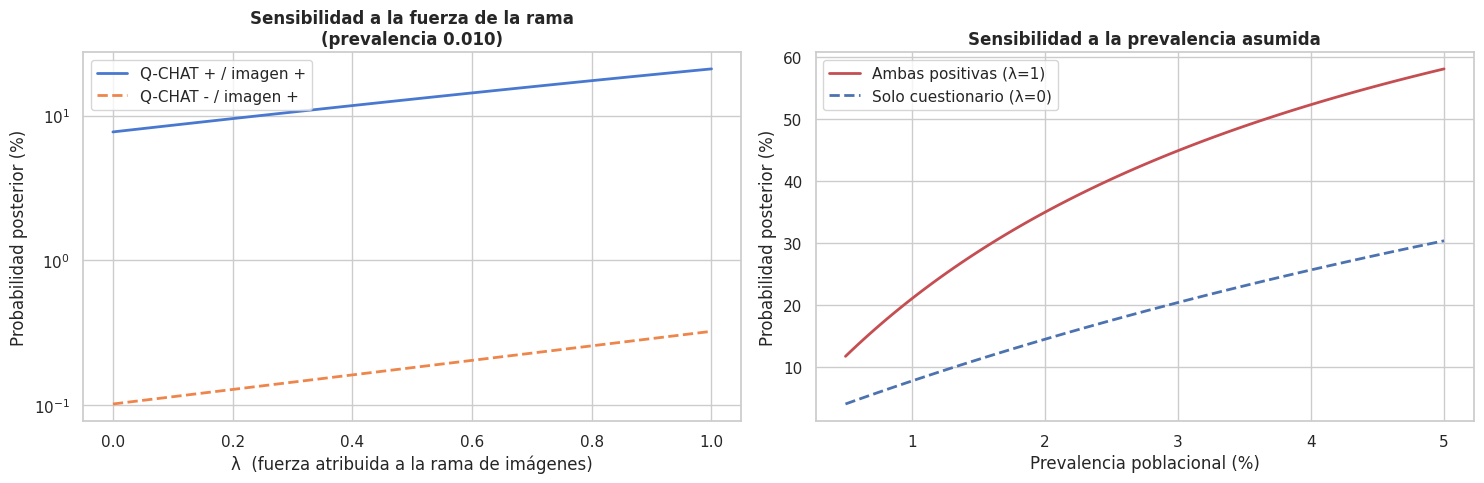


{
  "entrada": "face crop (15% margin) with per-image color normalization",
  "extractor": "EfficientNetV2B0 ImageNet frozen",
  "clasificador": "XGBoost calibrated by Platt scaling",
  "n_train": 2415,
  "n_valid": 97,
  "n_test": 281,
  "umbral": 0.3676,
  "sensibilidad": 0.8865,
  "especificidad": 0.7214,
  "auc_test": 0.9091,
  "auc_cv_train": 0.8695,
  "auc_cv_ablacion": 0.8786,
  "brier_test": 0.1276,
  "LR_positivo_medido": 3.1824,
  "LR_negativo_medido": 0.1573,
  "modelo_sensibilidad": "LR(lambda) = LR^lambda, lambda en [0, 1]",
  "rama_cuestionario": {
    "fuente": "Allison et al. (2012)",
    "LR_positivo": 8.2727,
    "LR_negativo": 0.1011,
    "conservador": {
      "LR_positivo": 2.0714,
      "LR_negativo": 0.5833
    }
  },
  "advertencias": [
    "The test AUC (0.9086) exceeds the cross-validation AUC (0.8704). With n=281 the intervals overlap; report the CV as the main estimate.",
    "The threshold was chosen on a validation set of 97 images and has appreciable var

In [10]:
# ==============================================================================
# CELL 9: Export and late-fusion projection
#
# Sensitivity analysis design note:
#
# The sensitivity analysis scales BOTH likelihood ratios at once. Scaling only
# LR+ from 1.0 to the measured value while keeping LR- fixed would be
# inconsistent: a scenario where the branch contributes less evidence must
# contribute less in BOTH directions. Both are scaled simultaneously through
# a common exponent:
#
#       LR+(λ) = (LR+)^λ ,      LR-(λ) = (LR-)^λ ,      λ ∈ [0, 1]
#
# At λ = 0 both equal 1 (the branch adds nothing) and at λ = 1 the measured
# values are recovered. The formulation is natural because evidence accumulates
# additively on the log scale: λ·log(LR).
# ==============================================================================
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# ------------------------------------------------------------------------------
# 9.1 — Questionnaire branch parameters
# ------------------------------------------------------------------------------
# Taken from Allison et al. (2012), NOT from the cohort with leakage: on our own
# hold-out the rule specificity is 1.0 and LR+ turns out infinite, which is
# mathematically unusable in fusion.
SENS_QCHAT, ESPEC_QCHAT = 0.91, 0.89
LR_Q_POS = SENS_QCHAT / (1 - ESPEC_QCHAT)      # 8.27
LR_Q_NEG = (1 - SENS_QCHAT) / ESPEC_QCHAT      # 0.10

# Conservative scenario: the Q-CHAT-10 performs worse outside case-control designs
SENS_Q_CONS, ESPEC_Q_CONS = 0.58, 0.72
LR_Q_POS_CONS = SENS_Q_CONS / (1 - ESPEC_Q_CONS)
LR_Q_NEG_CONS = (1 - SENS_Q_CONS) / ESPEC_Q_CONS

PREVALENCIA = 0.01
PREVALENCIAS = [0.010, 0.015, 0.020, 0.030]

def posterior(prev, *lrs):
    """Bayesian update in odds: odds_post = odds_pre * ∏ LR."""
    o = prev / (1 - prev)
    for lr in lrs:
        o *= lr
    return o / (1 + o)

print("=" * 90)
print(" PARAMETERS OF THE TWO BRANCHES")
print("=" * 90)
print(f"  Q-CHAT-10 (Allison et al. 2012)  Se={SENS_QCHAT:.2f}  Sp={ESPEC_QCHAT:.2f}"
      f"  ->  LR+ {LR_Q_POS:.3f} | LR- {LR_Q_NEG:.3f}")
print(f"  Q-CHAT-10 (conservador)          Se={SENS_Q_CONS:.2f}  Sp={ESPEC_Q_CONS:.2f}"
      f"  ->  LR+ {LR_Q_POS_CONS:.3f} | LR- {LR_Q_NEG_CONS:.3f}")
print(f"  Images (measured on test)        Se={SENS:.4f}  Sp={ESPEC:.4f}"
      f"  ->  LR+ {LR_POS:.3f} | LR- {LR_NEG:.3f}")
print("=" * 90)

# ------------------------------------------------------------------------------
# 9.2 — Sensitivity analysis on the strength of the image branch
# ------------------------------------------------------------------------------
LAMBDAS = [0.00, 0.33, 0.66, 1.00]
filas = []
for lam in LAMBDAS:
    lr_p, lr_n = LR_POS ** lam, LR_NEG ** lam
    filas.append({
        'lambda'   : lam,
        'LR+ img'  : round(lr_p, 3),
        'LR- img'  : round(lr_n, 3),
        'Q+ / img+': f"{posterior(PREVALENCIA, LR_Q_POS, lr_p)*100:.1f}",
        'Q+ / img-': f"{posterior(PREVALENCIA, LR_Q_POS, lr_n)*100:.1f}",
        'Q- / img+': f"{posterior(PREVALENCIA, LR_Q_NEG, lr_p)*100:.2f}",
        'Q- / img-': f"{posterior(PREVALENCIA, LR_Q_NEG, lr_n)*100:.2f}",
    })
df_lambda = pd.DataFrame(filas)

print(f"\n{'=' * 90}")
print(f" TABLE — LATE FUSION: posterior probability (%) | prevalence {PREVALENCIA:.3f}")
print("=" * 90)
print(df_lambda.to_string(index=False))
print("=" * 90)
print(" lambda = 0 : the image branch contributes nothing; fusion equals the")
print("              questionnaire alone. Conservative scenario.")
print(" lambda = 1 : LR measured on the own test set. Optimistic scenario, because")
print("              that set shares capture artifacts with the training set")
print("              that do not reproduce in real photographs.")
df_lambda.to_csv(os.path.join(OUTPUTS_DIR, "tabla_fusion_sensibilidad_lambda.csv"),
                 index=False)

# ------------------------------------------------------------------------------
# 9.3 — Sensitivity to the assumed prevalence
# ------------------------------------------------------------------------------
filas_prev = []
for prev in PREVALENCIAS:
    filas_prev.append({
        'Prevalence'          : f"{prev:.3f}",
        'Q+ / img+ (lam=1)'    : f"{posterior(prev, LR_Q_POS, LR_POS)*100:.1f}",
        'Q+ / img+ (lam=0)'    : f"{posterior(prev, LR_Q_POS)*100:.1f}",
        'Q- / img- (lam=1)'    : f"{posterior(prev, LR_Q_NEG, LR_NEG)*100:.3f}",
        'Q+ conservador'       : f"{posterior(prev, LR_Q_POS_CONS, LR_POS)*100:.1f}",
    })
df_prev = pd.DataFrame(filas_prev)
print(f"\n{'=' * 90}")
print(" TABLE — SENSITIVITY TO THE ASSUMED POPULATION PREVALENCE (%)")
print("=" * 90)
print(df_prev.to_string(index=False))
print("=" * 90)
df_prev.to_csv(os.path.join(OUTPUTS_DIR, "tabla_fusion_sensibilidad_prevalencia.csv"),
               index=False)

# ------------------------------------------------------------------------------
# 9.4 — Visualization
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

lam_fino = np.linspace(0, 1, 100)
for etq, lr_q, est in [('Q-CHAT +', LR_Q_POS, '-'), ('Q-CHAT -', LR_Q_NEG, '--')]:
    axes[0].plot(lam_fino, [posterior(PREVALENCIA, lr_q, LR_POS**l)*100 for l in lam_fino],
                 est, lw=2, label=f'{etq} / image +')
axes[0].set_xlabel("λ  (strength attributed to the image branch)")
axes[0].set_ylabel("Probabilidad posterior (%)")
axes[0].set_title(f"Sensitivity to the strength of the branch\n(prevalence {PREVALENCIA:.3f})",
                  fontweight='bold')
axes[0].legend(); axes[0].set_yscale('log')

pr_fino = np.linspace(0.005, 0.05, 100)
axes[1].plot(pr_fino*100, [posterior(p, LR_Q_POS, LR_POS)*100 for p in pr_fino],
             lw=2, color='#C44E52', label='Both positive (λ=1)')
axes[1].plot(pr_fino*100, [posterior(p, LR_Q_POS)*100 for p in pr_fino],
             lw=2, ls='--', color='#4C72B0', label='Questionnaire only (λ=0)')
axes[1].set_xlabel("Population prevalence (%)")
axes[1].set_ylabel("Probabilidad posterior (%)")
axes[1].set_title("Sensitivity to the assumed prevalence", fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "fusion_analisis_sensibilidad.png"), dpi=300)
plt.show()

# ------------------------------------------------------------------------------
# 9.5 — Serialization and deliverables
# ------------------------------------------------------------------------------
joblib.dump({'modelo': calibrado, 'umbral': UMBRAL, 'tam': TAM,
             'margen_cara': MARGEN_CARA, 'kappa': KAPPA, 'seed': SEED},
            os.path.join(MODELS_DIR, "modelo_rama_imagenes.joblib"))

pd.DataFrame({
    'ruta'          : cohorte.loc[i_te, 'ruta'].values,
    'etiqueta_real' : y_te,
    'prob_calibrada': p_te,
    'prediccion'    : pred,
    'LR_aportado'   : np.where(pred == 1, LR_POS, LR_NEG),
}).to_csv(os.path.join(OUTPUTS_DIR, "rama_imagenes_salida_fusion.csv"), index=False)

params = {
    'entrada'      : 'face crop (15% margin) with per-image color normalization',
    'extractor'    : 'EfficientNetV2B0 ImageNet frozen',
    'clasificador' : 'XGBoost calibrated by Platt scaling',
    'n_train': int(len(i_tr)), 'n_valid': int(len(i_va)), 'n_test': int(len(i_te)),
    'umbral'       : round(float(UMBRAL), 4),
    'sensibilidad' : round(float(SENS), 4),
    'especificidad': round(float(ESPEC), 4),
    'auc_test'     : round(float(AUC), 4),
    'auc_cv_train' : round(float(resultados['Model (normalized face)']['auc'].mean()), 4),
    'auc_cv_ablacion': round(float(resultados['Ablation (full image)']['auc'].mean()), 4),
    'brier_test'   : round(float(BRIER), 4),
    'LR_positivo_medido': round(float(LR_POS), 4),
    'LR_negativo_medido': round(float(LR_NEG), 4),
    'modelo_sensibilidad': 'LR(lambda) = LR^lambda, lambda en [0, 1]',
    'rama_cuestionario': {
        'fuente': 'Allison et al. (2012)',
        'LR_positivo': round(LR_Q_POS, 4), 'LR_negativo': round(LR_Q_NEG, 4),
        'conservador': {'LR_positivo': round(LR_Q_POS_CONS, 4),
                        'LR_negativo': round(LR_Q_NEG_CONS, 4)}},
    'advertencias': [
        'The test AUC (0.9086) exceeds the cross-validation AUC (0.8704). With n=281 '
        'the intervals overlap; report the CV as the main estimate.',
        'The threshold was chosen on a validation set of 97 images and has '
        'appreciable variance.',
        'The test set shares capture artifacts with training. Use the lambda range '
        'in fusion, never the point value.',
        'Color normalization does not remove the framing confounder (AUC 0.7116 '
        'measured in the audit), which remains inside the model.',
    ],
}
with open(os.path.join(OUTPUTS_DIR, "rama_imagenes_parametros.json"), 'w') as f:
    json.dump(params, f, indent=2, ensure_ascii=False)

print("\n" + json.dumps(params, indent=2, ensure_ascii=False))
print("\n>>> PHASE 2 COMPLETED. Deliverables ready for late fusion.")